In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("WELFake_Dataset.csv")

In [3]:
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [4]:
df.shape

(72134, 4)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


In [6]:
df.isnull().sum()

Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,Unnamed: 0,label
count,72134.000000,72134.000000
mean,36066.500000,0.514404
std,20823.436496,0.499796
min,0.000000,0.000000
25%,18033.250000,0.000000
50%,36066.500000,1.000000
75%,54099.750000,1.000000
max,72133.000000,1.000000


In [9]:
df.columns

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='object')

In [10]:
df = df.drop('Unnamed: 0', axis=1)

In [11]:
df = df.dropna(subset=['title', 'text'])

In [12]:
df.isnull().sum()

title    0
text     0
label    0
dtype: int64

In [13]:
df.shape

(71537, 3)

In [14]:
df['label'].value_counts()

label
1    36509
0    35028
Name: count, dtype: int64

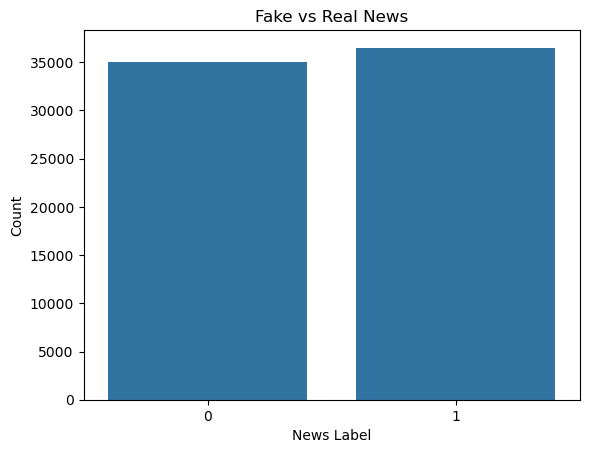

In [15]:
sns.countplot(x='label', data=df)

plt.title('Fake vs Real News')
plt.xlabel('News Label')
plt.ylabel('Count')

plt.show()

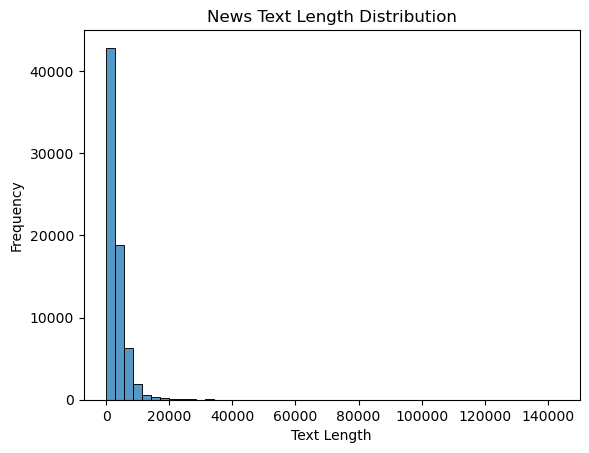

In [16]:
df['text_length'] = df['text'].apply(len)

sns.histplot(df['text_length'], bins=50)

plt.title('News Text Length Distribution')
plt.xlabel('Text Length')
plt.ylabel('Frequency')

plt.show()

In [17]:
df['content'] = df['title'] + " " + df['text']

df[['title', 'text', 'content']].head()

,title,text,content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",SATAN 2: Russia unvelis an image of its terrif...
5,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,About Time! Christian Group Sues Amazon and SP...


In [18]:
import re

In [19]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [20]:
df['cleaned_content'] = df['content'].apply(clean_text)

In [21]:
df[['content', 'cleaned_content']].head()

,content,cleaned_content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,law enforcement on high alert following threat...
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,unbelievable obama s attorney general says mos...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",bobby jindal raised hindu uses story of christ...
4,SATAN 2: Russia unvelis an image of its terrif...,satan russia unvelis an image of its terrifyin...
5,About Time! Christian Group Sues Amazon and SP...,about time christian group sues amazon and spl...


In [22]:
df.shape

(71537, 6)

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [24]:
X = df['cleaned_content']
y = df['label']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 57229
Testing data: 14308


In [ ]:
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Create models
lr_model = LogisticRegression(max_iter=1000, random_state=42)
nb_model = MultinomialNB()
svm_model = LinearSVC(random_state=42)

# Train models
lr_model.fit(X_train_tfidf, y_train)
nb_model.fit(X_train_tfidf, y_train)
svm_model.fit(X_train_tfidf, y_train)

print("All models trained successfully!")


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predictions
lr_pred = lr_model.predict(X_test_tfidf)
nb_pred = nb_model.predict(X_test_tfidf)
svm_pred = svm_model.predict(X_test_tfidf)

# Evaluation function
def evaluate_model(name, y_test, y_pred):
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))

# Evaluate all models
evaluate_model("Logistic Regression", y_test, lr_pred)
evaluate_model("Naive Bayes", y_test, nb_pred)
evaluate_model("SVM", y_test, svm_pred)


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, labels=[0, 1]
)
plt.title("Logistic Regression")
plt.show()

# Naive Bayes
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_pred, labels=[0, 1]
)
plt.title("Naive Bayes")
plt.show()

# SVM
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred, labels=[0, 1]
)
plt.title("SVM")
plt.show()


In [ ]:

from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred))

print("\nNAIVE BAYES")
print(classification_report(y_test, nb_pred))

print("\nSVM")
print(classification_report(y_test, svm_pred))


In [ ]:

def predict_news(news):
    cleaned_news = clean_text(news)
    news_tfidf = tfidf.transform([cleaned_news])

    prediction = svm_model.predict(news_tfidf)

    if prediction[0] == 0:
        print("Prediction: Fake News")
    else:
        print("Prediction: Real News")


# Test with new news
news = input("Enter news text: ")

predict_news(news)


In [ ]:

import joblib

# Save trained SVM model
joblib.dump(svm_model, "fake_news_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF Vectorizer saved successfully!")


In [ ]:

!pip install streamlit


In [ ]:

%%writefile fake_news_app.py

import streamlit as st
import joblib
import re

# Load saved model and vectorizer
model = joblib.load("fake_news_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

# Text cleaning
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Website title
st.title("Fake News Detection System")
st.write("Enter a news article to check whether it is Fake or Real.")

# User input
news = st.text_area("Enter News Article")

# Prediction button
if st.button("Predict"):
    if news.strip():
        cleaned_news = clean_text(news)
        news_tfidf = tfidf.transform([cleaned_news])
        prediction = model.predict(news_tfidf)

        if prediction[0] == 0:
            st.error("Prediction: Fake News")
        else:
            st.success("Prediction: Real News")
    else:
        st.warning("Please enter a news article.")


In [ ]:
!streamlit run fake_news_app.py

In [ ]:
!pip show streamlit

In [33]:
print("Kernel is working!")

Kernel is working!


In [34]:
print("X_train:", 'X_train' in globals())
print("X_test:", 'X_test' in globals())
print("y_train:", 'y_train' in globals())
print("y_test:", 'y_test' in globals())

X_train: True
X_test: True
y_train: True
y_test: True


In [35]:
print("TF-IDF:", 'tfidf' in globals())
print("X_train_tfidf:", 'X_train_tfidf' in globals())
print("X_test_tfidf:", 'X_test_tfidf' in globals())

TF-IDF: True
X_train_tfidf: True
X_test_tfidf: True


In [36]:
print("Logistic Regression:", 'lr_model' in globals())
print("Naive Bayes:", 'nb_model' in globals())
print("SVM:", 'svm_model' in globals())

Logistic Regression: True
Naive Bayes: True
SVM: True


In [37]:
print("SVM model:", svm_model)
print("Test predictions:", svm_model.predict(X_test_tfidf[:5]))

SVM model: LinearSVC(random_state=42)
Test predictions: [1 1 1 1 1]


In [38]:
import os

print("Model file:", os.path.exists("fake_news_model.pkl"))
print("TF-IDF file:", os.path.exists("tfidf_vectorizer.pkl"))
print("App file:", os.path.exists("fake_news_app.py"))

Model file: True
TF-IDF file: True
App file: True


In [39]:
import streamlit
print(streamlit.__version__)

1.51.0


In [40]:
import os
print(os.getcwd())

C:\Users\HP\datascience\machine learning


In [41]:
import sys
print(sys.executable)

C:\Users\HP\anaconda3\python.exe
